RNN and GRU text classification project (IMDB)
What this notebook does (short):
- Uses the official Keras `imdb` dataset (25k train / 25k test movie reviews)
- Builds and trains two models: a SimpleRNN-based classifier and a GRU-based classifier.
- Explains each code block with inline markdown and comments.
- Saves models, produces training plots

1) Imports and setup
  We'll import TensorFlow/Keras, plotting utilities and set a reproducible seed.

In [1]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# reproducibility 
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


2025-08-14 12:08:44.535740: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755173324.766255      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755173324.836392      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow version: 2.18.0


2) Load the official IMDB dataset
 We'll use `keras.datasets.imdb`, which is built-in and official. We'll keep top 10,000 words and pad sequences to length 200.

In [2]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000  # keep top 10k words
MAX_LEN = 200        # max tokens per review (pad/truncate)

print("Loading IMDB dataset (this uses Keras built-in) ...")
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print("Train examples:", len(x_train), "Test examples:", len(x_test))

# pad sequences
x_train = pad_sequences(x_train, maxlen=MAX_LEN, padding='post', truncating='post')
x_test = pad_sequences(x_test, maxlen=MAX_LEN, padding='post', truncating='post')

print("x_train shape:", x_train.shape)
print("x_test shape:", x_test.shape)


Loading IMDB dataset (this uses Keras built-in) ...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train examples: 25000 Test examples: 25000
x_train shape: (25000, 200)
x_test shape: (25000, 200)


3) Build helper functions: plot history, compile & fit
 Small helper to plot training curves and a function to compile & train models with consistent settings.

In [3]:
import matplotlib.pyplot as plt

def plot_history(history, title=None):
    """Plot accuracy and loss curves from a Keras History object."""
    plt.figure(figsize=(12,4))
    # accuracy
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label='train')
    plt.plot(history.history['val_accuracy'], label='val')
    plt.title('Accuracy' + (f" - {title}" if title else ''))
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    # loss
    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.title('Loss' + (f" - {title}" if title else ''))
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()


def compile_and_train(model, x_train, y_train, x_val, y_val, epochs=5, batch_size=128):
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=batch_size
    )
    return history

4) Train a SimpleRNN baseline
 Architecture:
- Embedding layer maps token ids to vectors
- SimpleRNN with 64 units
- Dense sigmoid output
 We'll hold out 5k training examples as validation.

In [4]:
EMBED_DIM = 128
RNN_UNITS = 64

# split train-> train_small + val
x_train_small = x_train[:-5000]
y_train_small = y_train[:-5000]

x_val = x_train[-5000:]
y_val = y_train[-5000:]

# build model
rnn_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=False),
    layers.SimpleRNN(RNN_UNITS, return_sequences=False),
    layers.Dense(1, activation='sigmoid')
], name='SimpleRNN_IMDB')

rnn_model.summary()

I0000 00:00:1755173381.910279      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "SimpleRNN_IMDB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

What this block does:
- Defines an embedding dimension and RNN unit count.
- Splits the training set: last 5k examples used for validation.
- Builds a Sequential model with an Embedding layer followed by a SimpleRNN and a Dense output.
- Prints model summary so you can see parameter counts.

Epoch 1/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.7940 - loss: 0.3291 - val_accuracy: 0.4998 - val_loss: 1.1716
Epoch 2/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7873 - loss: 0.3366 - val_accuracy: 0.5064 - val_loss: 1.3394
Epoch 3/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8011 - loss: 0.3216 - val_accuracy: 0.5116 - val_loss: 1.2079
Epoch 4/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7933 - loss: 0.3158 - val_accuracy: 0.5014 - val_loss: 1.1764
Epoch 5/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7725 - loss: 0.3366 - val_accuracy: 0.5010 - val_loss: 1.1813
Epoch 6/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.7779 - loss: 0.3521 - val_accuracy: 0.5050 - val_loss: 1.2298


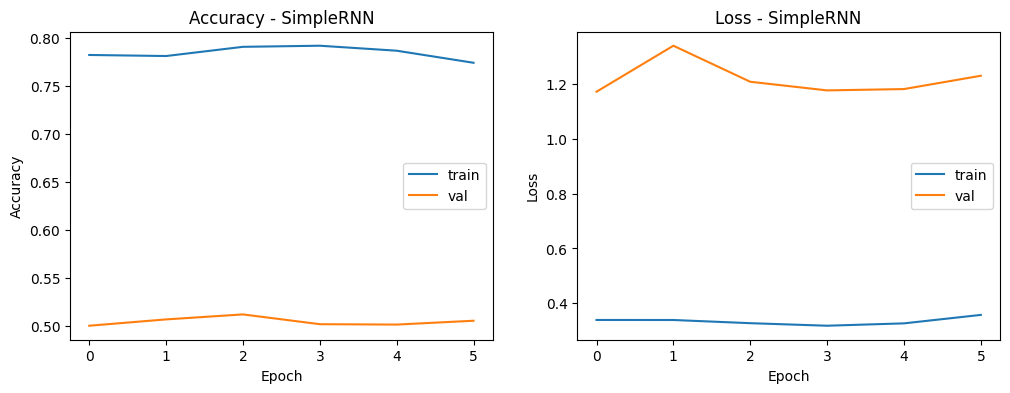

782/782 - 4s - 6ms/step - accuracy: 0.4983 - loss: 1.2171
SimpleRNN test accuracy: 0.4983


In [7]:
history_rnn = compile_and_train(rnn_model, x_train_small, y_train_small, x_val, y_val, epochs=6, batch_size=128)
plot_history(history_rnn, title='SimpleRNN')

# evaluate on test set
rnn_test_loss, rnn_test_acc = rnn_model.evaluate(x_test, y_test, verbose=2)
print(f"SimpleRNN test accuracy: {rnn_test_acc:.4f}")

# save model
rnn_model.save('simple_rnn_imdb.h5')

5) Train a GRU model
 Replace SimpleRNN with a GRU layer (same number of units). GRUs typically train faster and perform better.

In [8]:
GRU_UNITS = 64

gru_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, mask_zero=False),
    layers.GRU(GRU_UNITS, return_sequences=False),
    layers.Dense(1, activation='sigmoid')
], name='GRU_IMDB')

gru_model.summary()

Model: "GRU_IMDB"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,317,313 (5.03 MB)

 Trainable params: 1,317,313 (5.03 MB)

 Non-trainable params: 0 (0.00 B)

What this block does:
- Creates a Sequential model using a `GRU` layer instead of `SimpleRNN`.
- GRU has internal gating; often leads to better learning on sequence data.

Epoch 1/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8905 - loss: 0.2738 - val_accuracy: 0.8602 - val_loss: 0.3520
Epoch 2/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9228 - loss: 0.2004 - val_accuracy: 0.8648 - val_loss: 0.3537
Epoch 3/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9405 - loss: 0.1599 - val_accuracy: 0.8632 - val_loss: 0.3856
Epoch 4/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9653 - loss: 0.1052 - val_accuracy: 0.8654 - val_loss: 0.4571
Epoch 5/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9820 - loss: 0.0635 - val_accuracy: 0.8614 - val_loss: 0.5262
Epoch 6/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9852 - loss: 0.0514 - val_accuracy: 0.8496 - val_loss: 0.5147


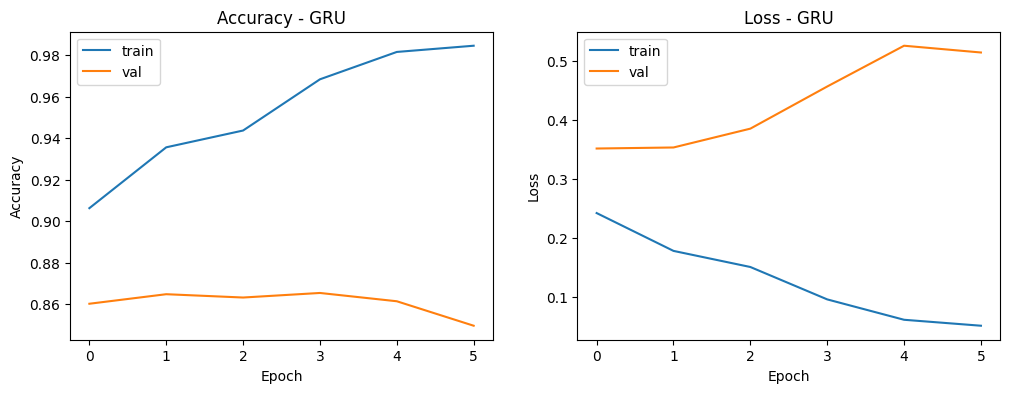

782/782 - 4s - 5ms/step - accuracy: 0.8289 - loss: 0.5617
GRU test accuracy: 0.8289


In [10]:
history_gru = compile_and_train(gru_model, x_train_small, y_train_small, x_val, y_val, epochs=6, batch_size=128)
plot_history(history_gru, title='GRU')

gru_test_loss, gru_test_acc = gru_model.evaluate(x_test, y_test, verbose=2)
print(f"GRU test accuracy: {gru_test_acc:.4f}")

gru_model.save('gru_imdb.h5')

6) Quick comparison and observations
 Print both test accuracies and give short notes on differences.

In [11]:
print(f"SimpleRNN test accuracy: {rnn_test_acc:.4f}")
print(f"GRU test accuracy:       {gru_test_acc:.4f}")

SimpleRNN test accuracy: 0.4983
GRU test accuracy:       0.8289
